In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from datasets import load_dataset
from collections import Counter

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

Device: cpu


In [4]:
from datasets import load_dataset

dataset = load_dataset(
    "katarinagresova/Genomic_Benchmarks_human_enhancers_cohn"
)

print(dataset)

README.md:   0%|          | 0.00/477 [00:00<?, ?B/s]

d:\Github\Personal_Projects\HelixRT\helix_rt\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\shiva\.cache\huggingface\hub\datasets--katarinagresova--Genomic_Benchmarks_human_enhancers_cohn. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Github\Personal_Projects\HelixRT\helix_rt\Lib\site-packages\hug

data/train-00000-of-00001-308a8a054210be(…): reconstructing file:   0%|          |  0.00B / 4.99MB            

data/train-00000-of-00001-308a8a054210be(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-b9d4d53093c0604(…): reconstructing file:   0%|          |  0.00B / 1.66MB            

data/test-00000-of-00001-b9d4d53093c0604(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/20843 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6948 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['seq', 'label'],
        num_rows: 20843
    })
    test: Dataset({
        features: ['seq', 'label'],
        num_rows: 6948
    })
})


In [5]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

print("\nColumns: ")
print(train_df.columns.tolist())

print("\nData types: ")
print(train_df.dtypes)

display(train_df.head())

Training dataset shape: (20843, 2)
Test dataset shape: (6948, 2)

Columns: 
['seq', 'label']

Data types: 
seq        str
label    int64
dtype: object


,seq,label
0,TGGTGGTACTTGTCAGGACTTGGAGCAGCAGGTGCAAGATTTAGTG...,0
1,TTCTTTTTTTGCCTTTTTATTATTTATTTATTTATTTATTTATTTA...,0
2,ATAACTGATGTTACAGAAATTCAAAGATTGTTTAGTGGCTACTGTG...,0
3,ATTAAGAAATGCTTTCCCACTCTAAAGGCATTTGACTATATTTTAT...,0
4,GAGGGGGTAATACAGAAATCACTTCTCAGCACATCAGCAGTTTGCT...,0


In [6]:
sample = train_df.iloc[0]

for column in train_df.columns:
    print(f"{column}:")
    print(str(sample[column])[:200])
    print()


seq:
TGGTGGTACTTGTCAGGACTTGGAGCAGCAGGTGCAAGATTTAGTGGGTTGGTTTTAGAATATCTGCTTGGAAAGTGGAAAAACTCAATGGATCATCTAGACTTTGGAATTTATCTCCTTCCCCACTTCTCCACTCCCCCAACAACAACAACAACAACAATGACAACAAAAACACCTGGAATAAACAGGTCATACAACGA

label:
0



Transformation

In [7]:
COMPLEMENT = str.maketrans("ACGTN", "TGCAN")

def reverse_complement(seq):
    seq = seq.upper()

    if not seq or set(seq) - set("ACGTN"):
        raise ValueError("Invalid nucleotide sequence")
    return seq.translate(COMPLEMENT)[::-1]

sequence = "ATGCCA"
print("Original: ", sequence)
print("Reverse complement: ", reverse_complement(sequence))

Original:  ATGCCA
Reverse complement:  TGGCAT


Cannonicalization

In [ ]:
def canonicalize(sequence):
    sequence = sequence.upper()
    rc = reverse_complement(sequence)

    return min(sequence, rc)

In [ ]:
seq = "ATGCCA"
rc = reverse_complement(seq)

print(canonicalize(seq))
print(canonicalize(rc))

ATGCCA
ATGCCA


Test Mathematically

These properties matter because our inference system will depend on them for correctness.
1. Involution: RC(RC(x))=x
2. Canonical equivalence: C(x)=C(RC(x))
3. Idempotence: C(C(x))=C(x)
4. Complexity: O(n) time and space

In [ ]:
test_sequences = [
    "ATGCCA",
    "AAAAAA",
    "ATAT",
    "CGCG",
    "ACGT",
    "ACNGT"
]

for seq in test_sequences:

    #Reverse complement is involution
    assert reverse_complement(reverse_complement(seq)) == seq

    #Both representations have the same key
    assert canonicalize(seq) == canonicalize(reverse_complement(seq))

    #canonicalize is idempotent
    assert canonicalize(canonicalize(seq)) == canonicalize(seq)

print("All tests passed.")

All tests passed.


## Exploratory Data Analysis

### Class Distribution

Inspect the distribution of target labels to identify class
imbalance and understand the classification baseline.


Train dataset:
label
0    10422
1    10421
Name: count, dtype: int64

Class proportions:
label
0    0.500024
1    0.499976
Name: proportion, dtype: float64

Test dataset:
label
0    3474
1    3474
Name: count, dtype: int64

Class proportions:
label
0    0.5
1    0.5
Name: proportion, dtype: float64


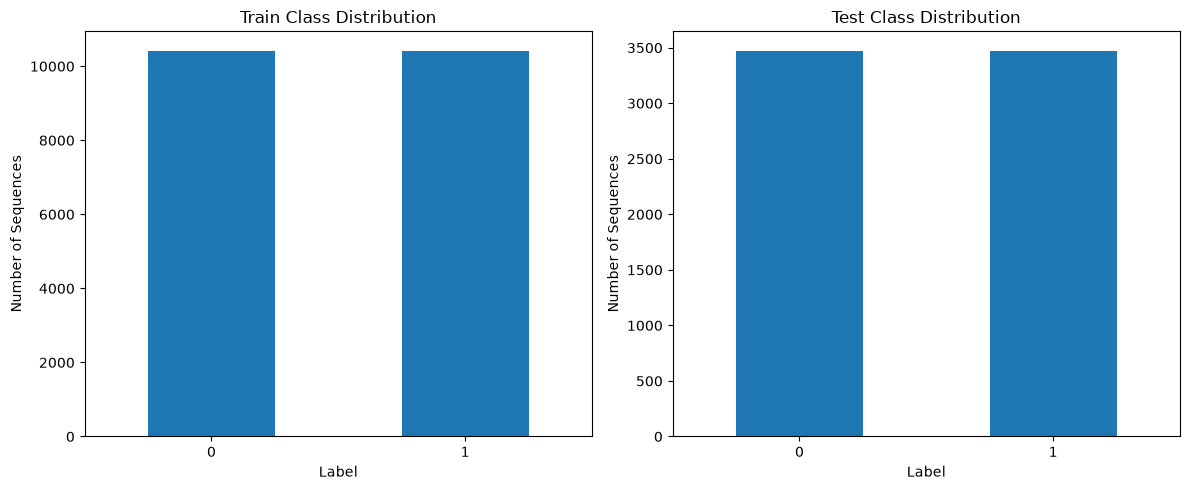

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, df, name in zip(axes, [train_df, test_df], ["Train", "Test"]):
    counts = df["label"].value_counts().sort_index()

    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"{name} Class Distribution")
    ax.set_xlabel("Label")
    ax.set_ylabel("Number of Sequences")
    ax.tick_params(axis="x", rotation=0)

    print(f"\n{name} dataset:")
    print(counts)

    print("\nClass proportions:")
    print(df["label"].value_counts(normalize=True))

plt.tight_layout()
plt.show()


### Sequence Length Analysis

In [13]:
train_df["length"] = train_df["seq"].str.len()
test_df["length"] = test_df["seq"].str.len()

print("Trianing sequence lengths: ")
print(train_df["length"].describe())

print("\nTest sequence lengths: ")
print(test_df["length"].describe())

print("\nUnique training sequence lengths" )
print(train_df["length"].nunique())

print("\nMost common sequence lengths:")
print(train_df["length"].value_counts().head(10))

Trianing sequence lengths: 
count    20843.0
mean       500.0
std          0.0
min        500.0
25%        500.0
50%        500.0
75%        500.0
max        500.0
Name: length, dtype: float64

Test sequence lengths: 
count    6948.0
mean      500.0
std         0.0
min       500.0
25%       500.0
50%       500.0
75%       500.0
max       500.0
Name: length, dtype: float64

Unique training sequence lengths
1

Most common sequence lengths:
length
500    20843
Name: count, dtype: int64


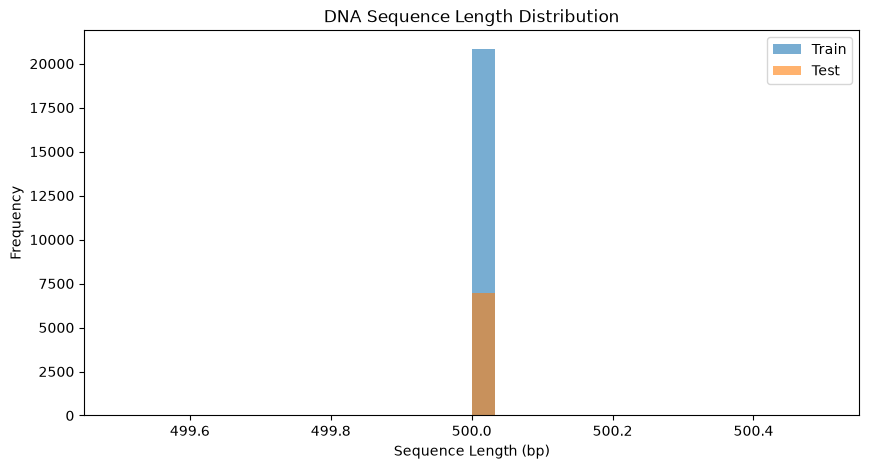

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_df["length"],
    bins=30,
    alpha=0.6,
    label="Train"
)

plt.hist(
    test_df["length"],
    bins=30,
    alpha=0.6,
    label="Test"
)

plt.xlabel("Sequence Length (bp)")
plt.ylabel("Frequency")
plt.title("DNA Sequence Length Distribution")
plt.legend()
plt.show()

### Nucleotide Distribution

In [15]:
def nucleotide_distribution(sequences):
    counts = Counter()

    for seq in sequences:
        counts.update(seq.upper())

    return pd.Series(counts).sort_index()

,Train,Test
A,0.284868,0.284024
C,0.215343,0.215904
G,0.214506,0.215683
T,0.285283,0.284389


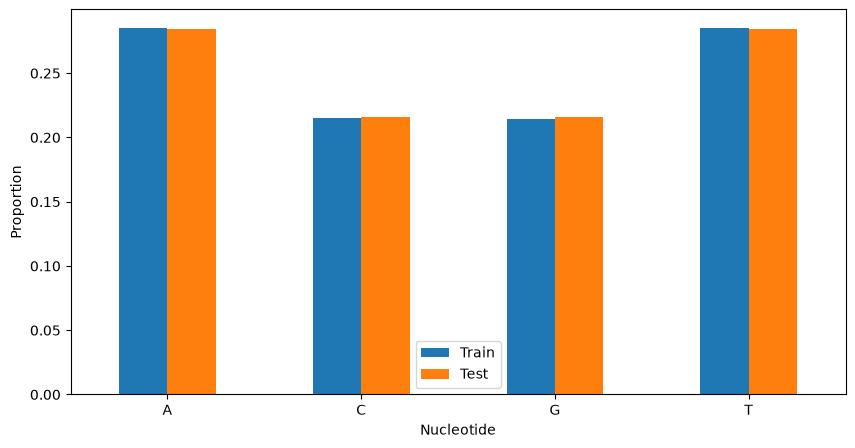

In [17]:
train_nucleotides = nucleotide_distribution(
    train_df["seq"]
)

test_nucleotides = nucleotide_distribution(
    test_df["seq"]
)

distribution = pd.DataFrame({
    "Train": train_nucleotides / train_nucleotides.sum(),
    "Test": test_nucleotides / test_nucleotides.sum()
})

display(distribution)

distribution.plot(kind="bar", figsize=(10,5), rot=0)
plt.xlabel("Nucleotide")
plt.ylabel("Proportion")
plt.show()

### Data Quality Checks

In [18]:
VALID_BASES = set("ACGTN")

def is_valid_sequence(seq):
    if not isinstance(seq,str):
        return False
    return bool(seq) and set(seq.upper()).issubset(VALID_BASES)
    

In [20]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    invalid_seqs = ~df["seq"].apply(is_valid_sequence)

    print(f"{name} dataset")
    print("-" * 30)

    print("Missing Sequences: ", df["seq"].isna().sum())
    print("Missing labels: ", df["label"].isna().sum())
    print("Invalid Sequences: ", invalid_seqs.sum())
    print("Sequences containing N: ", df["seq"].str.contains("N", case=False, na=False).sum())
    print("Unique labels: ", df["label"].unique())

Train dataset
------------------------------
Missing Sequences:  0
Missing labels:  0
Invalid Sequences:  0
Sequences containing N:  0
Unique labels:  [0 1]
Test dataset
------------------------------
Missing Sequences:  0
Missing labels:  0
Invalid Sequences:  0
Sequences containing N:  0
Unique labels:  [0 1]


### GC Content Analysis
GC content is the proportion of called nucleotides in a DNA sequence that are guanine or cytosine.
It is a useful genomic sequence characteristic and could potentially act as a simple predictive feature.

$$GC(x)=\frac{G+C}{A+T+G+C}$$


In [21]:
def gc_content(seq):
    seq = seq.upper()

    gc = seq.count("G") + seq.count("C")
    called_bases = sum(seq.count(b) for b in "ACGT")

    if called_bases == 0:
        return np.nan
    return gc / called_bases

In [22]:
train_df["gc_content"] = train_df["seq"].apply(gc_content)
test_df["gc_content"] = test_df["seq"].apply(gc_content)
display(train_df.groupby("label")["gc_content"].describe())

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,10422.0,0.39208,0.072146,0.036,0.34,0.386,0.438,0.820
1,10421.0,0.46762,0.092699,0.156,0.40,0.456,0.524,0.826


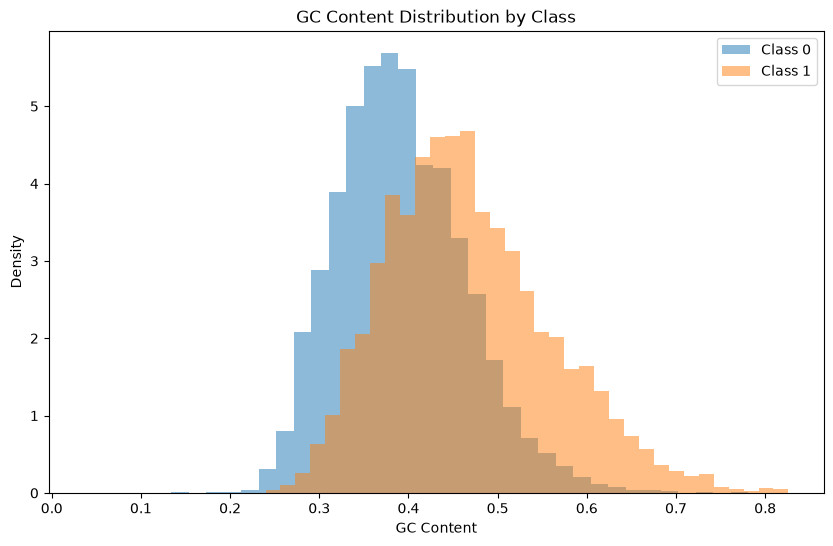

In [24]:
plt.figure(figsize=(10, 6))

for label in sorted(train_df["label"].unique()):
    subset = train_df[train_df["label"] == label]

    plt.hist(
        subset["gc_content"],
        bins=40,
        alpha=0.5,
        label=f"Class {label}",
        density=True
    )
plt.xlabel("GC Content")
plt.ylabel("Density")
plt.title("GC Content Distribution by Class")
plt.legend()
plt.show()



### Reverse-complement leakage audit

In [26]:
def canonicalize(sequence):

    sequence = sequence.upper()

    return min(
        sequence,
        reverse_complement(sequence)
    )

In [27]:
train_df["canonical_seq"] = train_df["seq"].apply(
    canonicalize
)

test_df["canonical_seq"] = test_df["seq"].apply(
    canonicalize
)

display(train_df.head())

,seq,label,length,gc_content,canonical_seq
0,TGGTGGTACTTGTCAGGACTTGGAGCAGCAGGTGCAAGATTTAGTG...,0,500,0.448,AGTAAGCCACAAGGTTGCTGGTGGCTCCTCCCTTCCCTGACTCTGG...
1,TTCTTTTTTTGCCTTTTTATTATTTATTTATTTATTTATTTATTTA...,0,500,0.426,TGAAGAGATACTGCACAAAAGAAGACAGGAGAATAGACAAAAATAC...
2,ATAACTGATGTTACAGAAATTCAAAGATTGTTTAGTGGCTACTGTG...,0,500,0.324,ATAACTGATGTTACAGAAATTCAAAGATTGTTTAGTGGCTACTGTG...
3,ATTAAGAAATGCTTTCCCACTCTAAAGGCATTTGACTATATTTTAT...,0,500,0.340,ATTAAGAAATGCTTTCCCACTCTAAAGGCATTTGACTATATTTTAT...
4,GAGGGGGTAATACAGAAATCACTTCTCAGCACATCAGCAGTTTGCT...,0,500,0.452,GAGGGGGTAATACAGAAATCACTTCTCAGCACATCAGCAGTTTGCT...


### Duplicate Analysis

In [29]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    exact_duplicates = df["seq"].duplicated().sum()
    canonical_duplicates = df["canonical_seq"].duplicated().sum()

    print(f"\n{name} dataset:")
    print("-" * 30)
    print(f"Exact duplicates: {exact_duplicates}")
    print(f"Canonical duplicates: {canonical_duplicates}")
    print(f"Additional RC duplicates: {canonical_duplicates - exact_duplicates}")


Train dataset:
------------------------------
Exact duplicates: 0
Canonical duplicates: 0
Additional RC duplicates: 0

Test dataset:
------------------------------
Exact duplicates: 0
Canonical duplicates: 0
Additional RC duplicates: 0


### Cross-Split leakage detection

In [30]:
train_sequences = set(train_df["seq"])
test_sequences = set(test_df["seq"])

exact_overlap = train_sequences.intersection(test_sequences)

train_canonical = set(train_df["canonical_seq"])
test_canonical = set(test_df["canonical_seq"])

canonical_overlap = train_canonical.intersection(test_canonical)

print("Unique exact overlapping sequences:", len(exact_overlap))

print("Unique overlapping canonical groups:", len(canonical_overlap))

print("Training rows affected:", train_df["canonical_seq"].isin(canonical_overlap).sum())

print("Test rows affected:", test_df["canonical_seq"].isin(canonical_overlap).sum())

Unique exact overlapping sequences: 0
Unique overlapping canonical groups: 0
Training rows affected: 0
Test rows affected: 0


### Check Conflicting Labels

Check whether biologically equivalent representations have been assignmed different labels

In [31]:
combined_df = pd.concat([
    train_df.assign(split="train"),
    test_df.assign(split="test")
], ignore_index=True)

label_counts = combined_df.groupby("canonical_seq")["label"].nunique()

conflicting_keys = label_counts[label_counts > 1].index

print("Conflicting canonical sequences:", len(conflicting_keys))

conflicting_samples = combined_df[combined_df["canonical_seq"].isin(conflicting_keys)]

display(conflicting_samples.head(10))

Conflicting canonical sequences: 0


,seq,label,length,gc_content,canonical_seq,split


## Dataset Preprocessing

### Stratified Training and Validation Split

Preserve the official test set and partition the original training set into training and validation subsets using stratified sampling and a fixed random seed.

In [32]:
from sklearn.model_selection import train_test_split

train_split, val_split = train_test_split(
    train_df, 
    test_size = 0.15, 
    stratify=train_df["label"], 
    random_state=SEED
)

train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)
test_split = test_df.reset_index(drop=True)

splits = {
    "train": train_split,
    "val": val_split,
    "test": test_split
}

for name, df in splits.items():
    print(f"\n{name.upper()}")
    print("Samples:", len(df))
    print(df["label"].value_counts().sort_index())


TRAIN
Samples: 17716
label
0    8858
1    8858
Name: count, dtype: int64

VAL
Samples: 3127
label
0    1564
1    1563
Name: count, dtype: int64

TEST
Samples: 6948
label
0    3474
1    3474
Name: count, dtype: int64


Verify Split Integrity

In [33]:
train_keys = set(train_split["canonical_seq"])
val_keys = set(val_split["canonical_seq"])
test_keys = set(test_split["canonical_seq"])

assert(train_keys.isdisjoint(val_keys))
assert(train_keys.isdisjoint(test_keys))
assert(val_keys.isdisjoint(test_keys))

assert(len(train_split) + len(val_split) == len(train_df))

print("All split integrity checks passed.")

All split integrity checks passed.


### One-hot nucleotide encoding

We need to convert each nucleotide into a numerical representation so that the DNA strings can be processed by the neural networks. For this, will use 4 channels, representing A, C, G and T

For our dataset:

| Dimension | Size |
|-----------|------|
| Channels | 4 |
| Sequence length |	500 |
| Values per sample | 2000 |

The channel-first representation is important because PyTorch's Conv1d expects inputs in the format (batch, channels, length).

Although this dataset does not contain 'N' nucleotides, we'll represent them as all-zero columns to support ambiguous bases in future inference requests.

In [34]:
BASES_TO_INDEX = {
    "A": 0,
    "C": 1,
    "G": 2,
    "T": 3
}

def one_hot_encode(seq):
    seq = seq.upper()

    encoded = np.zeros((4, len(seq)), dtype=np.float32)

    for position, base in enumerate(seq):
        if base in BASES_TO_INDEX:
            channel = BASES_TO_INDEX[base]
            encoded[channel, position] = 1.0
        elif base != "N":
            raise ValueError(f"Invalid nucleotide: {base}")

    return encoded

In [36]:
seq = "ATGCCA"
encoded = one_hot_encode(seq)
print("Sequence: ", seq)
print("Shape: ", encoded.shape)
print("Encoded: \n", encoded)

Sequence:  ATGCCA
Shape:  (4, 6)
Encoded: 
 [[1. 0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 1. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]]


### Tensor-level reverse complement

This is an essential component for HelixRT. During model training, our DNA sequences will already exist as tensors. Converting them back into strings, generating reverse complements and encoding them again would introduce unnecessary overhead. Instead, we can perform the transformation directly on the tensor.

The transformation consists of two operations:
1. Swap complementary nucleotide channels.
2. Reverse the sequence dimension.

This implementation supports both individual sequences and batches.

In [37]:
def reverse_complement_tensor(x):
    # Channel Order: A, C, G, T
    # Complement Order: T, G, C, A

    x = x[..., [3,2,1,0], :]
    return torch.flip(x, dims=[-1])


In [38]:
seq = "ATGCCA"

original_tensor = torch.from_numpy(one_hot_encode(seq))

expected_tensor = torch.from_numpy(one_hot_encode(reverse_complement(seq)))

actual_tensor = reverse_complement_tensor(original_tensor)

assert torch.equal(expected_tensor, actual_tensor)
assert torch.equal(reverse_complement_tensor(actual_tensor), original_tensor)

print("Tensor reverse complement test passed.")

Tensor reverse complement test passed.


### Save the processed datasets

In [39]:
from pathlib import Path

PROJECT_ROOT = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

for name, df in splits.items():
    output_path = PROCESSED_DIR / f"{name}.csv"
    df[["seq", "label", "gc_content"]].to_csv(output_path, index=False)

    print(f"Saved {name} to {output_path}")

Saved train to d:\Github\Personal_Projects\HelixRT\data\processed\train.csv
Saved val to d:\Github\Personal_Projects\HelixRT\data\processed\val.csv
Saved test to d:\Github\Personal_Projects\HelixRT\data\processed\test.csv
